### Graz Results

In [44]:
import os
from sqlalchemy import create_engine
db_url = (
    f"postgresql://{os.getenv('POSTGRES_USER')}:"
    f"{os.getenv('POSTGRES_PASSWORD')}@"
    f"localhost:5455/"
    f"{os.getenv('POSTGRES_DB')}"
)

engine = create_engine(db_url)

In [23]:
%load_ext autoreload
%autoreload 2
from prepare_graz_validation import add_station_dataset
import pandas as pd

path_stations_count = "../validation/stations_datasets/processed/graz_stations_count.csv"
path_stations_ref = "../validation/stations_datasets/processed/graz_stations_ref.json"

input_query = "SELECT * FROM results_graz_base_betweenness"
add_station_dataset(input_query,counting_stations_count_path=path_stations_count,counting_stations_ref_path=path_stations_ref,
                    counting_stations_count_table="counting_stations_count",counting_stations_ref_table="counting_stations_ref", 
                    city_name = 'Graz')
query = """SELECT * FROM counting_stations_count WHERE fetched_city = 'Graz'"""
graz_df = pd.read_sql(query,engine)
graz_df["date"] = pd.to_datetime(graz_df["time"]).dt.date
daily_df = graz_df[["id","date","count","count_sim"]].groupby(["id","date","count_sim"],as_index=False).sum()
num_days_df = daily_df[["id","date"]].groupby(["id"],as_index=False).count().rename(columns={"date":"num_days"})
total_count_df = daily_df[["id","count","count_sim"]].groupby(["id","count_sim"],as_index=False).sum()
average_daily_df_base = pd.merge(total_count_df,num_days_df)
average_daily_df_base = average_daily_df_base.rename(columns={"count_sim": "count_base"})
average_daily_df_base["count_aadt"] = average_daily_df_base["count"] / average_daily_df_base["num_days"]
average_daily_df_base 

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


,id,count_base,count,num_days,count_aadt
0,GRZ_102,5514,4.363644e+05,267,1634.323467
1,GRZ_103,1500,2.530088e+05,362,698.919419
2,GRZ_1091,6936,4.146141e+04,28,1480.764537
3,GRZ_1092,885,3.607671e+05,365,988.402904
4,GRZ_1116,2486,1.856256e+05,313,593.053149
5,GRZ_1152,162,1.442596e+05,366,394.151798
6,GRZ_390,2319,3.505091e+05,366,957.675031
7,GRZ_501,5755,6.288633e+05,366,1718.205615
8,GRZ_558,5948,2.951030e+06,366,8062.923561
9,GRZ_569,3657,7.661069e+05,364,2104.689173


In [20]:
import geopandas as gpd

count_df = pd.read_sql(query,engine)
df_ref = gpd.GeoDataFrame.from_file(path_stations_ref)
df_ref

,id,fetched_city,geometry
0,GRZ_1091,Graz,POINT (15.43509 47.07279)
1,GRZ_1092,Graz,POINT (15.41417 47.10408)
2,GRZ_922,Graz,POINT (15.41218 47.06368)
3,GRZ_922,Graz,POINT (15.41252 47.06369)
4,GRZ_390,Graz,POINT (15.42252 47.09412)
5,GRZ_569,Graz,POINT (15.45899 47.06149)
6,GRZ_1116,Graz,POINT (15.40279 47.07064)
7,GRZ_905,Graz,POINT (15.40899 47.06996)
8,GRZ_905,Graz,POINT (15.40944 47.06982)
9,GRZ_905,Graz,POINT (15.40948 47.06995)


In [21]:
ref_merged_df = df_ref.merge(count_df["id"], on="id", how="inner").drop_duplicates()
ref_merged_df

,id,fetched_city,geometry
0,GRZ_1091,Graz,POINT (15.43509 47.07279)
418,GRZ_1092,Graz,POINT (15.41417 47.10408)
8098,GRZ_922,Graz,POINT (15.41218 47.06368)
14994,GRZ_922,Graz,POINT (15.41252 47.06369)
21890,GRZ_390,Graz,POINT (15.42252 47.09412)
30104,GRZ_569,Graz,POINT (15.45899 47.06149)
38726,GRZ_1116,Graz,POINT (15.40279 47.07064)
45475,GRZ_905,Graz,POINT (15.40899 47.06996)
52914,GRZ_905,Graz,POINT (15.40944 47.06982)
60353,GRZ_905,Graz,POINT (15.40948 47.06995)


In [22]:
ref_merged_df.to_postgis("real_graz_stations",engine)

In [60]:
input_query = "SELECT * FROM results_graz_new_base_pois"
add_station_dataset(input_query,counting_stations_count_path=path_stations_count,counting_stations_ref_path=path_stations_ref,
                    counting_stations_count_table="counting_stations_count",counting_stations_ref_table="counting_stations_ref", 
                    city_name = 'Graz')
query = """SELECT * FROM counting_stations_count WHERE fetched_city = 'Graz'"""
graz_df = pd.read_sql(query,engine)
graz_df["date"] = pd.to_datetime(graz_df["time"]).dt.date
daily_df = graz_df[["id","date","count","count_sim"]].groupby(["id","date","count_sim"],as_index=False).sum()
num_days_df = daily_df[["id","date"]].groupby(["id"],as_index=False).count().rename(columns={"date":"num_days"})
total_count_df = daily_df[["id","count","count_sim"]].groupby(["id","count_sim"],as_index=False).sum()
average_daily_df_base_pois = pd.merge(total_count_df,num_days_df)
average_daily_df_base_pois = average_daily_df_base_pois.rename(columns={"count_sim": "count_base_pois"})
average_daily_df_base_pois["count_aadt"] = average_daily_df_base_pois["count"] / average_daily_df_base_pois["num_days"]
average_daily_df_base_pois 

,id,count_base_pois,count,num_days,count_aadt
0,GRZ_102,5119,4.363644e+05,267,1634.323467
1,GRZ_103,2519,2.530088e+05,362,698.919419
2,GRZ_1091,4262,4.146141e+04,28,1480.764537
3,GRZ_1092,907,3.607671e+05,365,988.402904
4,GRZ_1116,1442,1.856256e+05,313,593.053149
5,GRZ_1152,374,1.442596e+05,366,394.151798
6,GRZ_390,1665,3.505091e+05,366,957.675031
7,GRZ_501,2626,6.288633e+05,366,1718.205615
8,GRZ_558,6129,2.951030e+06,366,8062.923561
9,GRZ_569,3314,7.661069e+05,364,2104.689173


In [61]:
input_query = "SELECT * FROM results_graz_base_dist"
add_station_dataset(input_query,counting_stations_count_path=path_stations_count,counting_stations_ref_path=path_stations_ref,
                    counting_stations_count_table="counting_stations_count",counting_stations_ref_table="counting_stations_ref", 
                    city_name = 'Graz')
query = """SELECT * FROM counting_stations_count WHERE fetched_city = 'Graz'"""
graz_df = pd.read_sql(query,engine)
graz_df["date"] = pd.to_datetime(graz_df["time"]).dt.date
daily_df = graz_df[["id","date","count","count_sim"]].groupby(["id","date","count_sim"],as_index=False).sum()
num_days_df = daily_df[["id","date"]].groupby(["id"],as_index=False).count().rename(columns={"date":"num_days"})
total_count_df = daily_df[["id","count","count_sim"]].groupby(["id","count_sim"],as_index=False).sum()
average_daily_df_base_nrd = pd.merge(total_count_df,num_days_df)
average_daily_df_base_nrd = average_daily_df_base_nrd.rename(columns={"count_sim": "count_base_nrd"})
average_daily_df_base_nrd["count_aadt"] = average_daily_df_base_nrd["count"] / average_daily_df_base_nrd["num_days"]
average_daily_df_base_nrd 

,id,count_base_nrd,count,num_days,count_aadt
0,GRZ_102,12569,4.363644e+05,267,1634.323467
1,GRZ_103,3762,2.530088e+05,362,698.919419
2,GRZ_1091,8290,4.146141e+04,28,1480.764537
3,GRZ_1092,1591,3.607671e+05,365,988.402904
4,GRZ_1116,3878,1.856256e+05,313,593.053149
5,GRZ_1152,652,1.442596e+05,366,394.151798
6,GRZ_390,3174,3.505091e+05,366,957.675031
7,GRZ_501,5951,6.288633e+05,366,1718.205615
8,GRZ_558,12467,2.951030e+06,366,8062.923561
9,GRZ_569,7022,7.661069e+05,364,2104.689173


In [62]:
input_query = "SELECT * FROM results_graz_new_base_dist"
add_station_dataset(input_query,counting_stations_count_path=path_stations_count,counting_stations_ref_path=path_stations_ref,
                    counting_stations_count_table="counting_stations_count",counting_stations_ref_table="counting_stations_ref", 
                    city_name = 'Graz')
query = """SELECT * FROM counting_stations_count WHERE fetched_city = 'Graz'"""
graz_df = pd.read_sql(query,engine)
graz_df["date"] = pd.to_datetime(graz_df["time"]).dt.date
daily_df = graz_df[["id","date","count","count_sim"]].groupby(["id","date","count_sim"],as_index=False).sum()
num_days_df = daily_df[["id","date"]].groupby(["id"],as_index=False).count().rename(columns={"date":"num_days"})
total_count_df = daily_df[["id","count","count_sim"]].groupby(["id","count_sim"],as_index=False).sum()
average_daily_df_base_dist = pd.merge(total_count_df,num_days_df)
average_daily_df_base_dist = average_daily_df_base_dist.rename(columns={"count_sim": "count_base_dist"})
average_daily_df_base_dist["count_aadt"] = average_daily_df_base_dist["count"] / average_daily_df_base_dist["num_days"]
average_daily_df_base_dist 

,id,count_base_dist,count,num_days,count_aadt
0,GRZ_102,4888,4.363644e+05,267,1634.323467
1,GRZ_103,1605,2.530088e+05,362,698.919419
2,GRZ_1091,4576,4.146141e+04,28,1480.764537
3,GRZ_1092,563,3.607671e+05,365,988.402904
4,GRZ_1116,1925,1.856256e+05,313,593.053149
5,GRZ_1152,214,1.442596e+05,366,394.151798
6,GRZ_390,1458,3.505091e+05,366,957.675031
7,GRZ_501,3430,6.288633e+05,366,1718.205615
8,GRZ_558,4834,2.951030e+06,366,8062.923561
9,GRZ_569,2652,7.661069e+05,364,2104.689173


In [76]:
input_query = "SELECT * FROM results_graz_final"
add_station_dataset(input_query,counting_stations_count_path=path_stations_count,counting_stations_ref_path=path_stations_ref,
                    counting_stations_count_table="counting_stations_count",counting_stations_ref_table="counting_stations_ref", 
                    city_name = 'Graz')
query = """SELECT * FROM counting_stations_count WHERE fetched_city = 'Graz'"""
graz_df = pd.read_sql(query,engine)
graz_df["date"] = pd.to_datetime(graz_df["time"]).dt.date
daily_df = graz_df[["id","date","count","count_sim"]].groupby(["id","date","count_sim"],as_index=False).sum()
num_days_df = daily_df[["id","date"]].groupby(["id"],as_index=False).count().rename(columns={"date":"num_days"})
total_count_df = daily_df[["id","count","count_sim"]].groupby(["id","count_sim"],as_index=False).sum()
average_daily_df_final= pd.merge(total_count_df,num_days_df)
average_daily_df_final["count_aadt"] = average_daily_df_final["count"] / average_daily_df_final["num_days"]
average_daily_df_final 

,id,count_sim,count,num_days,count_aadt
0,GRZ_102,9349,4.363644e+05,267,1634.323467
1,GRZ_103,3820,2.530088e+05,362,698.919419
2,GRZ_1091,7199,4.146141e+04,28,1480.764537
3,GRZ_1092,1433,3.607671e+05,365,988.402904
4,GRZ_1116,3085,1.856256e+05,313,593.053149
5,GRZ_1152,602,1.442596e+05,366,394.151798
6,GRZ_390,3207,3.505091e+05,366,957.675031
7,GRZ_501,4636,6.288633e+05,366,1718.205615
8,GRZ_558,12532,2.951030e+06,366,8062.923561
9,GRZ_569,6058,7.661069e+05,364,2104.689173


In [79]:
from functools import reduce

list_df = [average_daily_df_base, average_daily_df_base_dist,average_daily_df_base_pois, average_daily_df_base_nrd, average_daily_df_final]

graz_df_raw = pd.concat(list_df, axis=1).T.drop_duplicates().T
graz_df_raw

,id,count_base,count,num_days,count_aadt,count_base_dist,count_base_pois,count_base_nrd,count_sim
0,GRZ_102,5514,436364.365681,267,1634.323467,4888,5119,12569,9349
1,GRZ_103,1500,253008.8296,362,698.919419,1605,2519,3762,3820
2,GRZ_1091,6936,41461.407047,28,1480.764537,4576,4262,8290,7199
3,GRZ_1092,885,360767.059986,365,988.402904,563,907,1591,1433
4,GRZ_1116,2486,185625.63577,313,593.053149,1925,1442,3878,3085
5,GRZ_1152,162,144259.558099,366,394.151798,214,374,652,602
6,GRZ_390,2319,350509.061483,366,957.675031,1458,1665,3174,3207
7,GRZ_501,5755,628863.254952,366,1718.205615,3430,2626,5951,4636
8,GRZ_558,5948,2951030.023193,366,8062.923561,4834,6129,12467,12532
9,GRZ_569,3657,766106.85897,364,2104.689173,2652,3314,7022,6058


In [80]:
graz_df = graz_df_raw[~graz_df_raw["id"].isin(["GRZ_749"])]
graz_df

,id,count_base,count,num_days,count_aadt,count_base_dist,count_base_pois,count_base_nrd,count_sim
0,GRZ_102,5514,436364.365681,267,1634.323467,4888,5119,12569,9349
1,GRZ_103,1500,253008.8296,362,698.919419,1605,2519,3762,3820
2,GRZ_1091,6936,41461.407047,28,1480.764537,4576,4262,8290,7199
3,GRZ_1092,885,360767.059986,365,988.402904,563,907,1591,1433
4,GRZ_1116,2486,185625.63577,313,593.053149,1925,1442,3878,3085
5,GRZ_1152,162,144259.558099,366,394.151798,214,374,652,602
6,GRZ_390,2319,350509.061483,366,957.675031,1458,1665,3174,3207
7,GRZ_501,5755,628863.254952,366,1718.205615,3430,2626,5951,4636
8,GRZ_558,5948,2951030.023193,366,8062.923561,4834,6129,12467,12532
9,GRZ_569,3657,766106.85897,364,2104.689173,2652,3314,7022,6058


In [81]:
graz_df["count_aadt"] = graz_df["count_aadt"].astype(float)
graz_df["count_base"] = graz_df["count_base"].astype(float)
graz_df["count_base_dist"] = graz_df["count_base_dist"].astype(float)
graz_df["count_base_pois"] = graz_df["count_base_pois"].astype(float)
graz_df["count_base_nrd"] = graz_df["count_base_nrd"].astype(float)
graz_df["count_sim"] = graz_df["count_sim"].astype(float)


In [82]:
graz_df["rank"] = graz_df["count_aadt"].rank(ascending=False)
graz_df["rank_base"] = graz_df["count_base"].rank(ascending=False)
graz_df["rank_base_dist"] = graz_df["count_base_dist"].rank(ascending=False)
graz_df["rank_base_pois"] = graz_df["count_base_pois"].rank(ascending=False)
graz_df["rank_base_nrd"] = graz_df["count_base_nrd"].rank(ascending=False)
graz_df["rank_sim"] = graz_df["count_sim"].rank(ascending=False)
graz_df

,id,count_base,count,num_days,count_aadt,count_base_dist,count_base_pois,count_base_nrd,count_sim,rank,rank_base,rank_base_dist,rank_base_pois,rank_base_nrd,rank_sim
0,GRZ_102,5514.0,436364.365681,267,1634.323467,4888.0,5119.0,12569.0,9349.0,5.0,5.0,2.0,3.0,2.0,3.0
1,GRZ_103,1500.0,253008.8296,362,698.919419,1605.0,2519.0,3762.0,3820.0,9.0,10.0,9.0,7.0,8.0,7.0
2,GRZ_1091,6936.0,41461.407047,28,1480.764537,4576.0,4262.0,8290.0,7199.0,6.0,2.0,4.0,4.0,4.0,4.0
3,GRZ_1092,885.0,360767.059986,365,988.402904,563.0,907.0,1591.0,1433.0,7.0,11.0,11.0,11.0,11.0,11.0
4,GRZ_1116,2486.0,185625.63577,313,593.053149,1925.0,1442.0,3878.0,3085.0,10.0,8.0,8.0,10.0,7.0,9.0
5,GRZ_1152,162.0,144259.558099,366,394.151798,214.0,374.0,652.0,602.0,11.0,12.0,12.0,12.0,12.0,12.0
6,GRZ_390,2319.0,350509.061483,366,957.675031,1458.0,1665.0,3174.0,3207.0,8.0,9.0,10.0,8.0,10.0,8.0
7,GRZ_501,5755.0,628863.254952,366,1718.205615,3430.0,2626.0,5951.0,4636.0,4.0,4.0,5.0,6.0,6.0,6.0
8,GRZ_558,5948.0,2951030.023193,366,8062.923561,4834.0,6129.0,12467.0,12532.0,1.0,3.0,3.0,2.0,3.0,2.0
9,GRZ_569,3657.0,766106.85897,364,2104.689173,2652.0,3314.0,7022.0,6058.0,3.0,7.0,7.0,5.0,5.0,5.0


In [83]:
graz_df[["count_aadt","count_base", "count_base_dist","count_base_pois","count_base_nrd",
        "count_sim"]].corr(method="kendall")

,count_aadt,count_base,count_base_dist,count_base_pois,count_base_nrd,count_sim
count_aadt,1.000000,0.454545,0.424242,0.636364,0.545455,0.666667
count_base,0.454545,1.000000,0.848485,0.696970,0.727273,0.666667
count_base_dist,0.424242,0.848485,1.000000,0.787879,0.878788,0.757576
count_base_pois,0.636364,0.696970,0.787879,1.000000,0.848485,0.969697
count_base_nrd,0.545455,0.727273,0.878788,0.848485,1.000000,0.878788
count_sim,0.666667,0.666667,0.757576,0.969697,0.878788,1.000000


In [84]:
from scipy.stats import pearsonr

res = pearsonr(graz_df["count_aadt"], graz_df["count_sim"])

print("Pearson correlation:", res.statistic)
print("p-value:", res.pvalue)

Pearson correlation: 0.8582773815848441
p-value: 0.00035318818510853673


In [85]:
graz_df[["rank","rank_base","rank_base_pois","rank_base_nrd",
         "rank_base_dist","rank_sim"]].corr(method="kendall")

,rank,rank_base,rank_base_pois,rank_base_nrd,rank_base_dist,rank_sim
rank,1.000000,0.454545,0.636364,0.545455,0.424242,0.666667
rank_base,0.454545,1.000000,0.696970,0.727273,0.848485,0.666667
rank_base_pois,0.636364,0.696970,1.000000,0.848485,0.787879,0.969697
rank_base_nrd,0.545455,0.727273,0.848485,1.000000,0.878788,0.878788
rank_base_dist,0.424242,0.848485,0.787879,0.878788,1.000000,0.757576
rank_sim,0.666667,0.666667,0.969697,0.878788,0.757576,1.000000


P-values
rank_base         0.018453
rank_base_dist    0.018453
rank_base_pois    0.000785
rank_base_nrd     0.003446
rank_sim          0.000521
Name: rank, dtype: float64


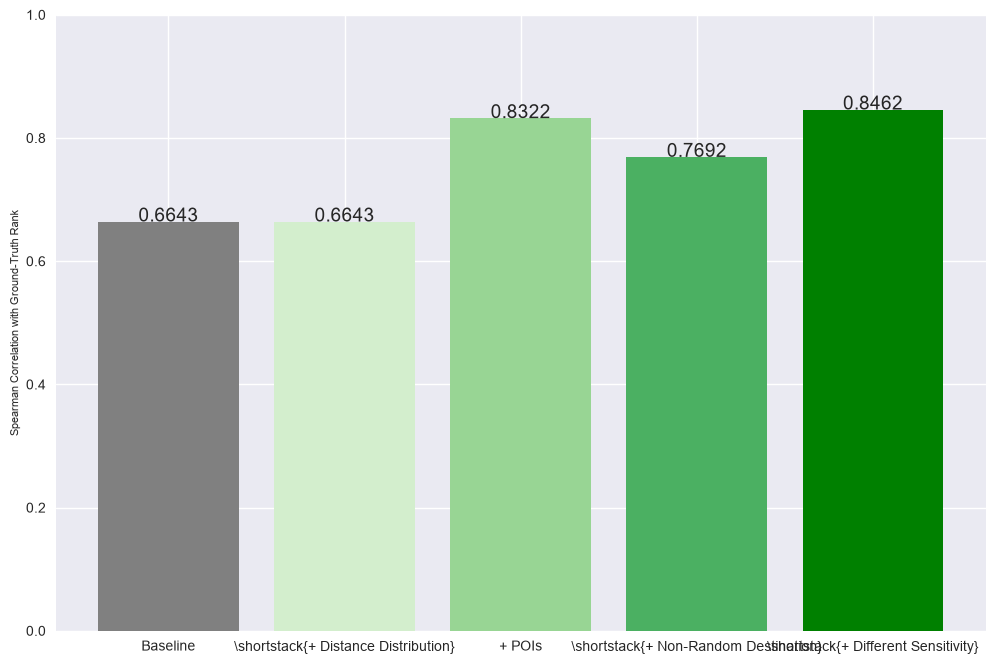

In [89]:
import seaborn as sns
import textwrap
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr, kendalltau, pearsonr

plt.figure(figsize=(12, 8))

plt.style.use('seaborn-v0_8')

corrs = (
    graz_df[["rank", "rank_base", "rank_base_dist","rank_base_pois","rank_base_nrd","rank_sim"]]
    .corr()["rank"]
    .drop("rank")
)

rank_df = graz_df[["rank", "rank_base","rank_base_dist", "rank_base_pois","rank_base_nrd","rank_sim"]]

corrs = (
    rank_df
    .corr()["rank"]
    .drop("rank")
)


corr_matrix, p_matrix = spearmanr(rank_df)


pval_df = pd.DataFrame(p_matrix,
                       index=rank_df.columns,
                       columns=rank_df.columns)
print("P-values")
print(pval_df["rank"]
    .drop("rank"))


labels = ["Baseline",r"\shortstack{+ Distance Distribution}", "+ POIs", r"\shortstack{+ Non-Random Destination}",
          r"\shortstack{+ Different Sensitivity}"]



middle_colors = plt.cm.Greens(np.linspace(0.2, 0.6, 3))

colors = (
    ["gray"] +                    
    list(middle_colors) +         
    ["green", "#6D3B07", "#EC1B2D"]    
)
plt.bar(
    x=labels,
    height=corrs.values, color=colors)

for i, v in enumerate(corrs.values):
    plt.text(i, v, f"{v:.4f}", ha="center",fontsize=14)

plt.ylim(0, 1)
plt.ylabel("Spearman Correlation with Ground-Truth Rank", fontsize = 8)
# plt.xlabel("Method")
#plt.xticks(rotation=45, ha="right", fontsize=6)

plt.savefig("figures/revision/graz_spearman")

import tikzplotlib

# plt.tight_layout()

tikzplotlib.save("figures/revision/graz_spearman.tex",
                 extra_axis_parameters=[
                r"xticklabel style={font=\fontsize{6}{10}\selectfont, rotate=45, anchor=east}",
                r"ylabel style={font=\fontsize{8}{10}\selectfont}"]
)

rank_base         0.044737
rank_base_dist    0.062869
rank_base_pois    0.003182
rank_base_nrd     0.013771
rank_sim          0.001803
Name: rank, dtype: float64


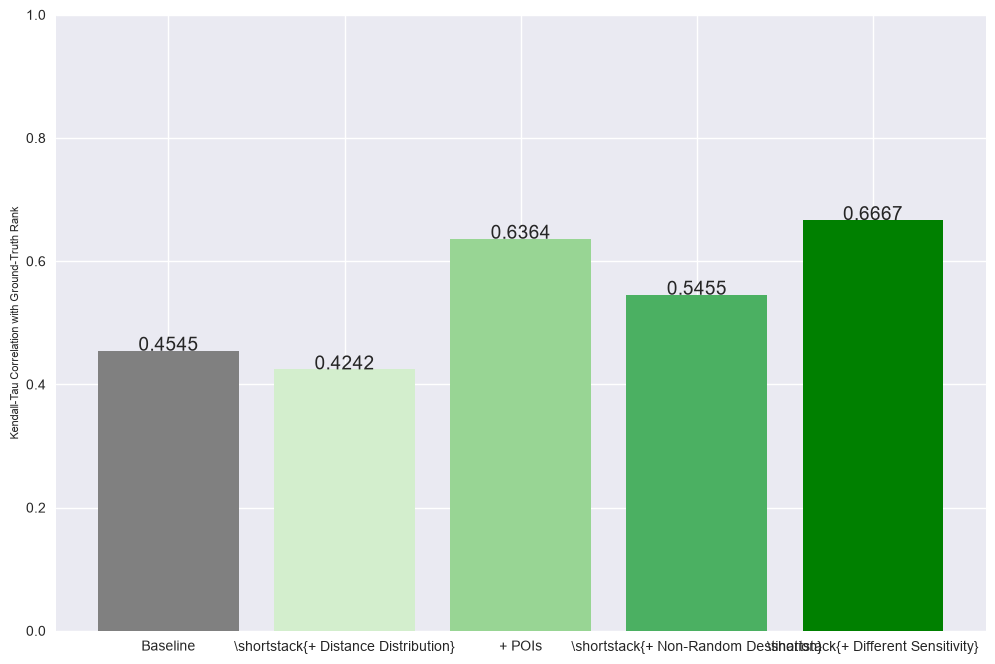

In [90]:
import seaborn as sns
import textwrap
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 8))

plt.style.use('seaborn-v0_8')

corrs = (
    graz_df[["rank", "rank_base", "rank_base_dist","rank_base_pois","rank_base_nrd","rank_sim"]]
    .corr(method="kendall")["rank"]
    .drop("rank")
)

rank_df = graz_df[["rank", "rank_base", "rank_base_dist","rank_base_pois","rank_base_nrd","rank_sim"]]


cols = rank_df.columns

corr_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)
p_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)

for c1 in cols:
    for c2 in cols:
        tau, pval = kendalltau(rank_df[c1], rank_df[c2])

        corr_matrix.loc[c1, c2] = tau
        p_matrix.loc[c1, c2] = pval

pval_df = pd.DataFrame(p_matrix, index=cols,columns=cols)



print(pval_df["rank"]
    .drop("rank"))



labels = ["Baseline",r"\shortstack{+ Distance Distribution}","+ POIs", r"\shortstack{+ Non-Random Destination}",
          r"\shortstack{+ Different Sensitivity}"]

wrapped_labels = [textwrap.fill(label, 14) for label in labels]

middle_colors = plt.cm.Greens(np.linspace(0.2, 0.6, 3))

colors = (
    ["gray"] +                    
    list(middle_colors) +         
    ["green", "#6D3B07", "#EC1B2D"]    
)
plt.bar(
    x=labels,
    height=corrs.values, color=colors)

for i, v in enumerate(corrs.values):
    plt.text(i, v, f"{v:.4f}", ha="center",fontsize=14)

plt.ylim(0, 1)
plt.ylabel("Kendall-Tau Correlation with Ground-Truth Rank", fontsize = 8)
# plt.xlabel("Method")
# plt.xticks(rotation=45, ha="right", fontsize=6)

plt.savefig("figures/revision/graz_kendalltau")

import tikzplotlib


tikzplotlib.save("figures/revision/graz_kendalltau.tex",
                 extra_axis_parameters=[
                r"xticklabel style={font=\fontsize{6}{10}\selectfont, rotate=45, anchor=east}",
                r"ylabel style={font=\fontsize{8}{10}\selectfont}"]
)

count_base         0.026325
count_base_dist    0.017805
count_base_pois    0.001365
count_base_nrd     0.003171
count_sim          0.000353
Name: count_aadt, dtype: float64


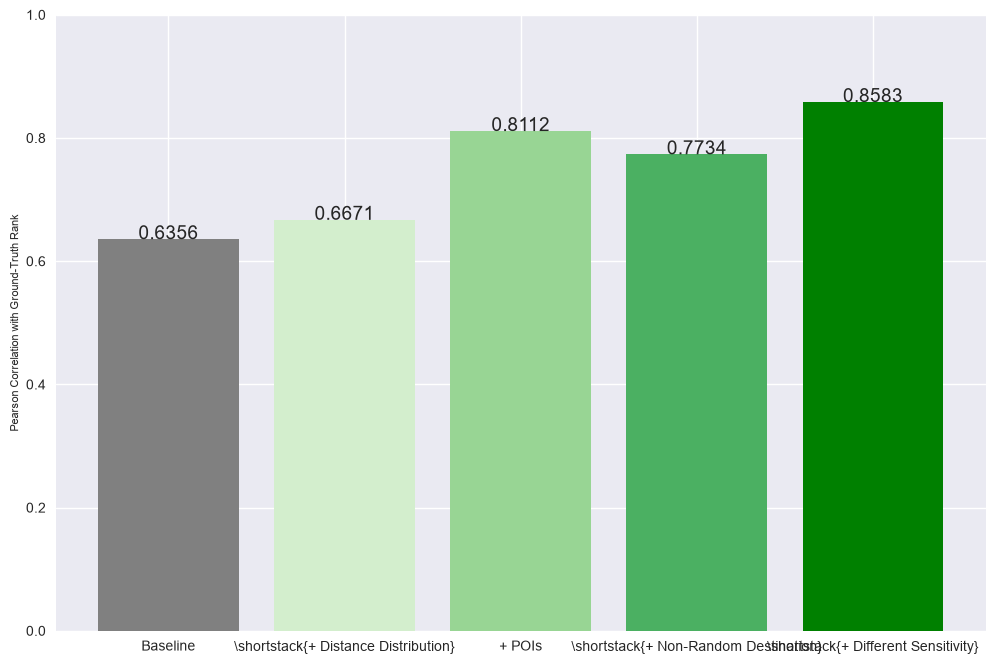

In [91]:
import seaborn as sns
import textwrap
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 8))

plt.style.use('seaborn-v0_8')

corrs = (
    graz_df[["count_aadt", "count_base", "count_base_dist","count_base_pois","count_base_nrd","count_sim"]]
    .corr(method="pearson")["count_aadt"]
    .drop("count_aadt")
)

count_df = graz_df[["count_aadt", "count_base","count_base_dist", "count_base_pois","count_base_nrd","count_sim"]]


cols = count_df.columns

corr_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)
p_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)

for c1 in cols:
    for c2 in cols:
        tau, pval = pearsonr(count_df[c1], count_df[c2])

        corr_matrix.loc[c1, c2] = tau
        p_matrix.loc[c1, c2] = pval

pval_df = pd.DataFrame(p_matrix, index=cols,columns=cols)



print(pval_df["count_aadt"]
    .drop("count_aadt"))


labels = ["Baseline", r"\shortstack{+ Distance Distribution}","+ POIs", r"\shortstack{+ Non-Random Destination}",
          r"\shortstack{+ Different Sensitivity}"]

wrapped_labels = [textwrap.fill(label, 14) for label in labels]

middle_colors = plt.cm.Greens(np.linspace(0.2, 0.6, 3))

colors = (
    ["gray"] +                    
    list(middle_colors) +         
    ["green", "#6D3B07", "#EC1B2D"]    
)
plt.bar(
    x=labels,
    height=corrs.values, color=colors)

for i, v in enumerate(corrs.values):
    plt.text(i, v, f"{v:.4f}", ha="center",fontsize=14)

plt.ylim(0, 1)
plt.ylabel("Pearson Correlation with Ground-Truth Rank", fontsize = 8)
# plt.xlabel("Method")
# plt.xticks(rotation=45, ha="right", fontsize=6)

plt.savefig("figures/revision/graz_pearson")

import tikzplotlib

tikzplotlib.save("figures/revision/graz_pearson.tex",
                 extra_axis_parameters=[
                r"xticklabel style={font=\fontsize{6}{10}\selectfont, rotate=45, anchor=east}",
                r"ylabel style={font=\fontsize{8}{10}\selectfont}"]
)